#Task 1: Data Preparation and Feature Engineering


In [16]:
# Import libraries and settings
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import os, datetime

START, END = '2021-01-01', '2025-01-01'   # END is exclusive
USE_CACHE = False                         # True = load saved files instead of downloading
os.makedirs('data', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

retrieval_date = datetime.date.today()
print('Retrieval date:', retrieval_date)
print('pandas', pd.__version__, '| numpy', np.__version__, '| yfinance', yf.__version__)

Retrieval date: 2026-11-23
pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66


## 1.1 Ticker selection and data acquisition
Tickers come from the Wikipedia S&P 500 table (current constituents). Prices come from `yfinance` (free, and gives both Close and Adjusted Close). `auto_adjust=False` keeps both prices. The benchmark is ^GSPC.

In [17]:
# Part 1: S&P 500 tickers from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
if not USE_CACHE:
    table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    sp500 = table[0][['Symbol', 'Security', 'GICS Sector', 'Date added']].copy()
    sp500['Retrieved'] = str(retrieval_date)
    sp500.to_csv('data/sp500_tickers.csv', index=False)
else:
    sp500 = pd.read_csv('data/sp500_tickers.csv')

tickers = [t.replace('.', '-') for t in sp500['Symbol']]   # BRK.B -> BRK-B for Yahoo
print('Total tickers:', len(tickers))
sp500.head()

Total tickers: 503


,Symbol,Security,GICS Sector,Date added,Retrieved
0,MMM,3M,Industrials,1957-03-04,2026-11-23
1,AOS,A. O. Smith,Industrials,2017-07-26,2026-11-23
2,ABT,Abbott Laboratories,Health Care,1957-03-04,2026-11-23
3,ABBV,AbbVie,Health Care,2012-12-31,2026-11-23
4,ACN,Accenture,Information Technology,2011-07-06,2026-11-23


In [18]:
# Part 2: download daily prices and volume (shares + benchmark)
if not USE_CACHE:
    shares = yf.download(tickers, start=START, end=END, auto_adjust=False)
    bench = yf.download('^GSPC', start=START, end=END, auto_adjust=False)
    close = shares['Close']
    adj = shares['Adj Close']
    volume = shares['Volume']
    bench_adj = bench['Adj Close'].squeeze()
    bench_close = bench['Close'].squeeze()
    # save a snapshot so the analysis can be repeated
    close.to_csv('data/close.csv'); adj.to_csv('data/adj_close.csv'); volume.to_csv('data/volume.csv')
    bench_adj.to_csv('data/bench_adj.csv'); bench_close.to_csv('data/bench_close.csv')
else:
    close = pd.read_csv('data/close.csv', index_col=0, parse_dates=True)
    adj = pd.read_csv('data/adj_close.csv', index_col=0, parse_dates=True)
    volume = pd.read_csv('data/volume.csv', index_col=0, parse_dates=True)
    bench_adj = pd.read_csv('data/bench_adj.csv', index_col=0, parse_dates=True).squeeze()
    bench_close = pd.read_csv('data/bench_close.csv', index_col=0, parse_dates=True).squeeze()

print('Price table (dates x tickers):', adj.shape)
print('Period:', adj.index.min().date(), 'to', adj.index.max().date())
adj.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'HONA', 'Q', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Price table (dates x tickers): (1005, 503)
Period: 2021-01-04 to 2024-12-31


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,125.537132,84.219139,139.149994,97.269707,33.186359,232.029327,485.339996,132.622604,42.189476,...,26.124491,102.852104,54.757374,33.042770,93.015877,221.160004,95.016182,141.603378,378.130005,152.952026
2021-01-05,114.941261,127.089241,85.090004,148.300003,98.473206,33.319485,233.350266,485.690002,134.993164,43.010098,...,26.371321,106.017509,54.223660,34.635189,92.903938,229.750000,95.025185,144.053375,380.570007,154.017853
2021-01-06,118.093239,122.811188,84.354958,142.770004,98.268158,34.783871,235.901611,466.309998,135.601700,44.752838,...,26.506685,106.652519,55.424545,35.518974,96.822739,226.889999,95.545959,148.158386,394.820007,156.280533
2021-01-07,121.235588,127.001900,85.257805,151.270004,99.222061,34.460564,238.127304,477.739990,141.332748,44.355217,...,26.761488,105.594193,54.340412,35.797653,101.217422,239.479996,94.818665,147.280045,409.100006,156.140228
2021-01-08,122.100456,128.098114,85.705208,149.770004,99.498421,34.650742,238.995819,485.100006,142.359085,44.473660,...,26.578352,104.901436,54.840778,36.195759,100.191055,241.449997,96.210419,146.956497,405.470001,157.178070


# **1.2 Data validation and alignment**
For each share I check: duplicate dates, missing prices, non-positive prices, volume errors, unequal history, and corporate actions. Any share that fails is removed and the reason is logged. Nothing is forward-filled.

In [19]:
# Part 3: validation checks
print('Duplicate dates (shares):', adj.index.duplicated().sum())
print('Duplicate dates (benchmark):', bench_adj.index.duplicated().sum())
print('Benchmark missing values:', bench_adj.isna().sum(), '| benchmark Close = Adj Close:', np.allclose(bench_close, bench_adj))

# use the benchmark trading days as the common calendar
calendar = bench_adj.dropna().index
print('Trading days in benchmark:', len(calendar))
print('Share dates not in benchmark calendar:', len(adj.index.difference(calendar)))

close = close.reindex(calendar)      # reindex shows gaps as NaN (it does not fill them)
adj = adj.reindex(calendar)
volume = volume.reindex(calendar)

checks = pd.DataFrame(index=tickers)
checks['missing_prices'] = adj.isna().sum().reindex(tickers).fillna(len(calendar))
checks['nonpositive_prices'] = ((adj <= 0) | (close <= 0)).sum().reindex(tickers).fillna(0)
checks['missing_volume'] = volume.isna().sum().reindex(tickers).fillna(len(calendar))
checks['negative_volume'] = (volume < 0).sum().reindex(tickers).fillna(0)
checks['zero_volume_days'] = (volume == 0).sum().reindex(tickers).fillna(0)
checks['first_date'] = [adj[t].first_valid_index() if t in adj else None for t in tickers]

checks['reason'] = ''
checks.loc[checks.missing_prices > 0, 'reason'] += 'missing prices / unequal history; '
checks.loc[checks.nonpositive_prices > 0, 'reason'] += 'non-positive price; '
checks.loc[checks.missing_volume > 0, 'reason'] += 'missing volume; '
checks.loc[checks.negative_volume > 0, 'reason'] += 'negative volume; '
checks.loc[checks.zero_volume_days > 0, 'reason'] += 'zero volume days; '

excluded = checks[checks.reason != '']
valid = [t for t in tickers if checks.loc[t, 'reason'] == '']
checks.to_csv('outputs/validation_log.csv')
excluded[['reason']].to_csv('outputs/exclusion_log.csv')
print('Valid shares:', len(valid), '| Excluded:', len(excluded))
print(excluded['reason'].value_counts())

Duplicate dates (shares): 0
Duplicate dates (benchmark): 0
Benchmark missing values: 0 | benchmark Close = Adj Close: True
Trading days in benchmark: 1005
Share dates not in benchmark calendar: 0
Valid shares: 486 | Excluded: 17
reason
missing prices / unequal history; missing volume;     15
zero volume days;                                      2
Name: count, dtype: int64


In [20]:
# Corporate actions: dividends change the Adj Close / Close ratio, splits cause big one-day moves
ratio = adj[valid] / close[valid]
dividend_days = ((ratio / ratio.shift(1) - 1).abs() > 0.00001).sum()
daily_move = adj[valid] / adj[valid].shift(1) - 1
big_moves = daily_move.abs().gt(0.35).sum()

print('Median number of dividend adjustments per share:', int(dividend_days.median()))
print('Shares with a daily move above 35% (check for splits):', int((big_moves > 0).sum()))
print(list(big_moves[big_moves > 0].index))
# Yahoo Close is already split-adjusted, and Volume is split-adjusted too,
# so Close x Volume is on a consistent basis.

Median number of dividend adjustments per share: 16
Shares with a daily move above 35% (check for splits): 8
['BIIB', 'BE', 'CVNA', 'DXCM', 'GL', 'NFLX', 'SMCI', 'VRT']


**Survivorship bias.** The Wikipedia list contains *current* constituents. Companies removed from the index between 2021 and 2025 are missing, and companies added during the period have short histories and are excluded. The sample therefore favours firms that survived, which can overstate historical returns and understate risk.

In [21]:
added = pd.to_datetime(sp500['Date added'], errors='coerce')
print('Current constituents added after', START, ':', (added >= START).sum())

Current constituents added after 2021-01-01 : 89


## 1.3 Weekly return and weekly beta
Weekly price = last available adjusted close in each Friday-ending week. Weekly return = this week's price / last week's price - 1. The incomplete first and last calendar weeks are dropped; holiday-shortened weeks are kept.

In [22]:
# Part 4: weekly prices (Friday-ending weeks)
weekly = adj[valid].resample('W-FRI').last()
bench_weekly = bench_adj.reindex(calendar).resample('W-FRI').last()

# drop incomplete first and last weeks
first_day, last_day = calendar[0], calendar[-1]
print('First trading day:', first_day.date(), '| Last trading day:', last_day.date())
if first_day.weekday() >= 2:            # data start after Tuesday -> first week incomplete
    weekly = weekly.iloc[1:]; bench_weekly = bench_weekly.iloc[1:]
if last_day.weekday() < 3:              # data end before Thursday -> last week incomplete
    weekly = weekly.iloc[:-1]; bench_weekly = bench_weekly.iloc[:-1]

# weekly returns (no filling of missing weeks)
weekly_returns = weekly / weekly.shift(1) - 1
bench_returns = bench_weekly / bench_weekly.shift(1) - 1
weekly_returns = weekly_returns.dropna(how='all')
bench_returns = bench_returns.loc[weekly_returns.index]

print('Weekly return dates:', weekly_returns.index[0].date(), 'to', weekly_returns.index[-1].date())
print('Same week labels for shares and benchmark:', (weekly_returns.index == bench_returns.index).all())
weekly_returns.iloc[:3, :5]

First trading day: 2021-01-04 | Last trading day: 2024-12-31
Weekly return dates: 2021-01-15 to 2024-12-27
Same week labels for shares and benchmark: True


Ticker,MMM,AOS,ABT,ABBV,ACN
Date,,,,,
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505
2021-01-22,0.021081,0.016364,0.013836,0.003076,0.004415
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050438


In [23]:
# 1.3.1 Mean weekly return (arithmetic mean)
mean_return = weekly_returns.mean()
n_weeks = weekly_returns.count()
print('Weekly observations per share:', n_weeks.min(), 'to', n_weeks.max())
print(mean_return.describe())

Weekly observations per share: 207 to 207
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64


In [24]:
# 1.3.2 Weekly beta = covariance(share, market) / variance(market)
beta_list = []
for share in weekly_returns.columns:
    pair = pd.concat([weekly_returns[share], bench_returns], axis=1).dropna()
    pair.columns = ['share', 'market']
    beta = pair['share'].cov(pair['market']) / pair['market'].var()
    beta_list.append(beta)
beta = pd.Series(beta_list, index=weekly_returns.columns)

# quick check with a regression slope: should be the same number
x = bench_returns.values
y = weekly_returns[valid[0]].values
print('Beta of', valid[0], ':', round(beta[valid[0]], 4), '| regression slope:', round(np.polyfit(x, y, 1)[0], 4))
print(beta.describe())

Beta of MMM : 0.8691 | regression slope: 0.8691
count    486.000000
mean       0.973695
std        0.407339
min        0.055453
25%        0.666599
50%        0.950610
75%        1.179538
max        3.778560
dtype: float64


In [25]:
# Why adjusted prices? Compare with Close-only returns
close_weekly = close[valid].resample('W-FRI').last().reindex(weekly.index)
close_returns = (close_weekly / close_weekly.shift(1) - 1).loc[weekly_returns.index]
diff = (close_returns.mean() - weekly_returns.mean()) * 10000
print('Average difference in mean weekly return (Close - Adj Close), basis points:', round(diff.mean(), 2))

Average difference in mean weekly return (Close - Adj Close), basis points: -3.47


## 1.4 Adapted RFM
* **Observation date** = final common trading date.
* **High-volume day** = volume greater than 2 x the mean volume of the previous 20 sessions (the day itself is not included).
* **R** = calendar days from the latest high-volume day to the observation date (no event = missing).
* **F** = number of high-volume days in the latest 60 sessions.
* **M** = sum of Close x Volume over the latest 60 sessions (USD).

In [26]:
# Part 5: high-volume days (separately for every share and day)
vol = volume[valid]
avg20 = vol.rolling(20).mean().shift(1)      # mean of the 20 sessions BEFORE each day
high_volume = vol > 2 * avg20                # True on a high-volume day

obs_date = calendar[-1]
last60 = calendar[-60:]
print('Observation date:', obs_date.date())
print('60-session window:', last60[0].date(), 'to', last60[-1].date())
print('Baseline available for whole window:', avg20.loc[last60].notna().all().all())

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Baseline available for whole window: True


In [27]:
# Recency, Frequency, Monetary
recency = {}
for share in valid:
    event_days = high_volume.index[high_volume[share]]
    if len(event_days) > 0:
        recency[share] = (obs_date - event_days[-1]).days     # calendar days
    else:
        recency[share] = np.nan                                # no event: missing, NOT zero
recency = pd.Series(recency)

frequency = high_volume.loc[last60].sum()
monetary = (close[valid] * volume[valid]).loc[last60].sum()

print('Shares with no high-volume event (R missing):', recency.isna().sum())
print('Shares with event on the observation date (R = 0):', (recency == 0).sum())

Shares with no high-volume event (R missing): 0
Shares with event on the observation date (R = 0): 0


In [28]:
print('Median Frequency:', frequency.median())
print('Maximum Frequency:', frequency.max())
print('Median Monetary ($ million):', round(monetary.median() / 1e6))

Median Frequency: 3.0
Maximum Frequency: 8
Median Monetary ($ million): 16684


In [29]:
example = 'AAPL' if 'AAPL' in valid else valid[0]
last_event = high_volume.index[high_volume[example]][-1]
print('Share:', example)
print('Latest high-volume day:', last_event.date())
print('R =', recency[example], 'days')
print('F =', int(frequency[example]), 'days')
print('M = $', round(monetary[example]))

Share: AAPL
Latest high-volume day: 2024-12-20
R = 11 days
F = 2 days
M = $ 623303377707


In [30]:
total = 0
count = 0
for d in last60:
    total += close[example][d] * vol[example][d]
    count += int(high_volume[example][d])
print('Loop F =', count, '| Loop M =', round(total))
print('Same as main calculation:', count == frequency[example] and round(total) == round(monetary[example]))

Loop F = 2 | Loop M = 623303377707
Same as main calculation: True


In [31]:
# Simple tests of the rule (example from the brief: 1 million average -> threshold 2 million)
def test(v):
    s = pd.Series([1000000] * 20 + [v])
    return bool((s > 2 * s.rolling(20).mean().shift(1)).iloc[-1])
print('2.5 million qualifies:', test(2500000))
print('1.8 million qualifies:', test(1800000))
print('exactly 2.0 million qualifies:', test(2000000), '(must be greater than, so False)')

# No look-ahead: changing the last day's volume must not change earlier flags
vol2 = vol.copy(); vol2.iloc[-1] = vol2.iloc[-1] * 1000
flags2 = vol2 > 2 * vol2.rolling(20).mean().shift(1)
print('Earlier flags unchanged:', (flags2.iloc[:-1] == high_volume.iloc[:-1]).all().all())

2.5 million qualifies: True
1.8 million qualifies: False
exactly 2.0 million qualifies: False (must be greater than, so False)
Earlier flags unchanged: True


## 1.5 Worked example and feature summary

In [32]:
# Worked example for one share
example = 'AAPL' if 'AAPL' in valid else valid[0]
table = pd.DataFrame({'Close': close[example], 'Volume': vol[example],
                      'Mean volume (previous 20)': avg20[example],
                      'Threshold (2x)': 2 * avg20[example],
                      'High volume?': high_volume[example],
                      'Close x Volume': close[example] * vol[example]}).loc[last60]
print('Example share:', example)
print('Latest high-volume day:', high_volume.index[high_volume[example]][-1].date())
print('R =', recency[example], 'days | F =', int(frequency[example]), 'days | M = $', round(monetary[example]))

# check M and F with a plain loop
total = 0; count = 0
for d in last60:
    total += close[example][d] * vol[example][d]
    count += int(high_volume[example][d])
print('Loop check -> F =', count, '| M =', round(total), '| same as above:', count == frequency[example] and round(total) == round(monetary[example]))
table.tail(5)

Example share: AAPL
Latest high-volume day: 2024-12-20
R = 11 days | F = 2 days | M = $ 623303377707
Loop check -> F = 2 | M = 623303377707 | same as above: True


,Close,Volume,Mean volume (previous 20),Threshold (2x),High volume?,Close x Volume
Date,,,,,,
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False,8.967601e+09
2024-12-31,250.419998,39480700,46921770.0,93843540.0,False,9.886757e+09


In [33]:
# Feature table: one row per valid share
features = pd.DataFrame({'Sector': sp500.set_index(sp500['Symbol'].str.replace('.', '-', regex=False))['GICS Sector'].reindex(valid),
                         'Mean_Weekly_Return': mean_return, 'Weekly_Beta': beta, 'Weekly_Obs': n_weeks,
                         'Recency': recency, 'Frequency': frequency, 'Monetary': monetary})
features['Common_Set'] = features[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].notna().all(axis=1)
features.index.name = 'Ticker'
features.to_csv('outputs/feature_table.csv')

print('Shares in feature table:', len(features))
print('Shares in common set for clustering (R not missing):', features['Common_Set'].sum())
print(features[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].describe().round(4))
print('Skew:'); print(features[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].skew().round(2))

Shares in feature table: 486
Shares in common set for clustering (R not missing): 486
       Mean_Weekly_Return  Weekly_Beta   Recency  Frequency      Monetary
count            486.0000     486.0000  486.0000   486.0000  4.860000e+02
mean               0.0029       0.9737   20.4074     2.9897  3.940419e+10
std                0.0027       0.4073   21.3424     1.3308  1.291388e+11
min               -0.0045       0.0555    4.0000     0.0000  1.297483e+09
25%                0.0012       0.6666   11.0000     2.0000  1.019517e+10
50%                0.0026       0.9506   11.0000     3.0000  1.668382e+10
75%                0.0042       1.1795   14.7500     4.0000  3.227689e+10
max                0.0178       3.7786  222.0000     8.0000  1.847697e+12
Skew:
Mean_Weekly_Return     0.87
Weekly_Beta            1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: float64


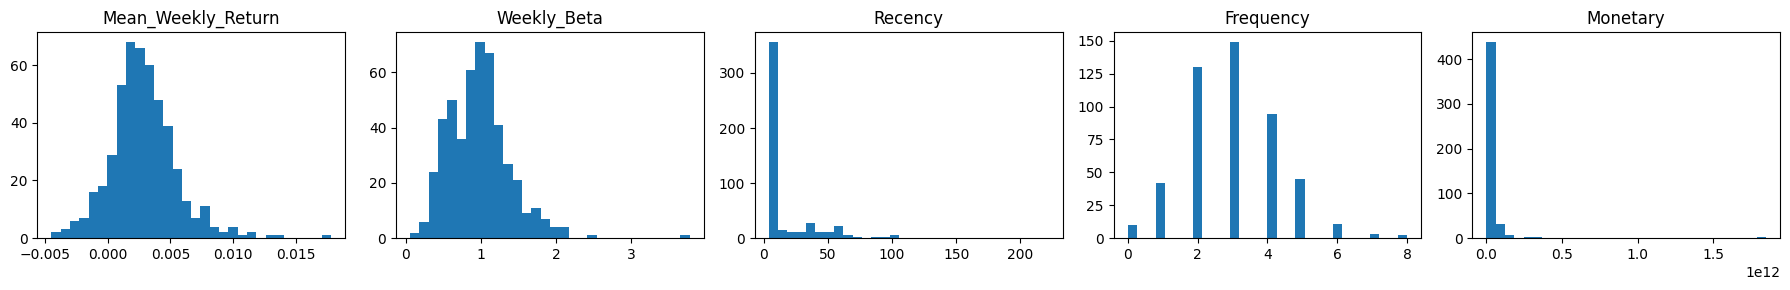

In [34]:
# Distributions
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col in zip(axes, ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']):
    ax.hist(features[col].dropna(), bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('outputs/feature_distributions.png', dpi=150)
plt.show()

# Task 2: Stock Segmentation and Sensitivity Analysis
This notebook uses the Task 1 feature table `feature_table.csv` (one row per share) with the columns:
Share, Sector, Mean_Weekly_Return, Beta, R, F, M

In [35]:
# Import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)

pandas 2.2.3 | scikit-learn 1.6.1 | scipy 1.16.3


## 2.1 Feature preparation

In [36]:
# Load the Task 1 feature table
df = pd.read_csv('outputs/feature_table.csv')
print('Shares in Task 1 table:', len(df))

# Remove shares with a missing value using the correct column names from Task 1
df = df.dropna(subset=['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']).reset_index(drop=True)
print('Shares used for clustering:', len(df))

Shares in Task 1 table: 486
Shares used for clustering: 486


In [37]:
# Inspect skew and outliers using the correct column names from Task 1
features = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']
print(df[features].describe())
print('\nSkewness:')
print(df[features].skew())

       Mean_Weekly_Return  Weekly_Beta     Recency   Frequency      Monetary
count          486.000000   486.000000  486.000000  486.000000  4.860000e+02
mean             0.002857     0.973695   20.407407    2.989712  3.940419e+10
std              0.002652     0.407339   21.342438    1.330800  1.291388e+11
min             -0.004468     0.055453    4.000000    0.000000  1.297483e+09
25%              0.001182     0.666599   11.000000    2.000000  1.019517e+10
50%              0.002619     0.950610   11.000000    3.000000  1.668382e+10
75%              0.004207     1.179538   14.750000    4.000000  3.227689e+10
max              0.017772     3.778560  222.000000    8.000000  1.847697e+12

Skewness:
Mean_Weekly_Return     0.867516
Weekly_Beta            1.103649
Recency                3.645784
Frequency              0.424735
Monetary              11.683797
dtype: float64


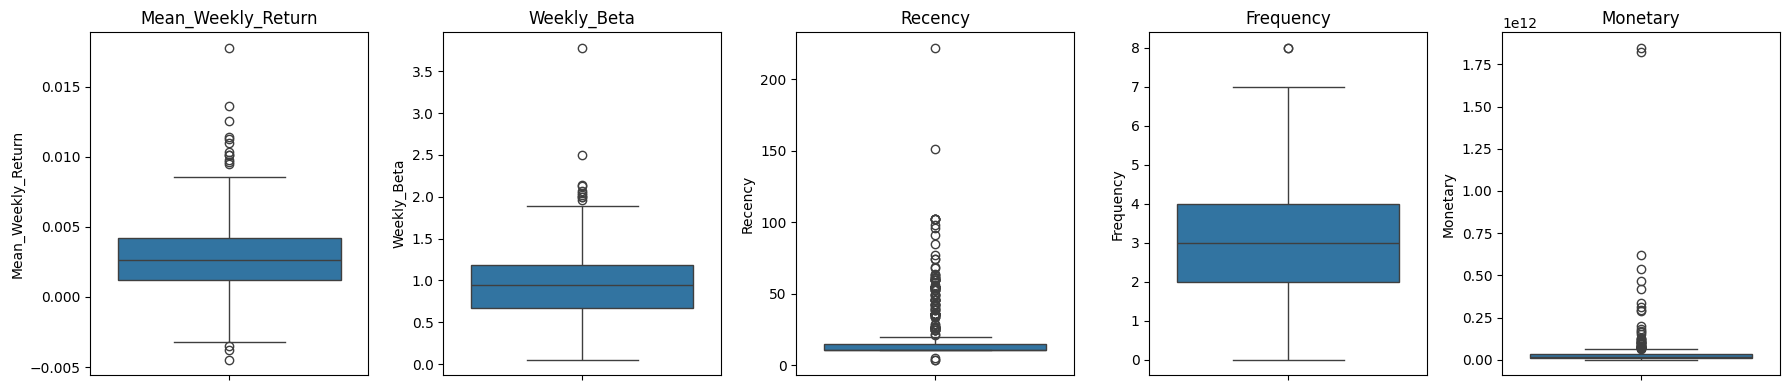

In [38]:
# Boxplots to see outliers
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

Skew of M before log1p: 11.68
Skew of M after log1p : 1.08


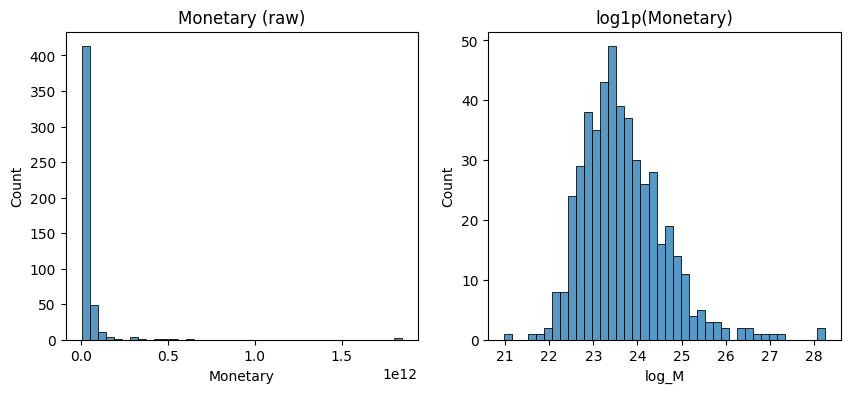

In [39]:
# Apply log1p to Monetary because it is strongly right-skewed
df['log_M'] = np.log1p(df['Monetary'])
print('Skew of M before log1p:', round(df['Monetary'].skew(), 2))
print('Skew of M after log1p :', round(df['log_M'].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df['Monetary'], bins=40, ax=axes[0]);     axes[0].set_title('Monetary (raw)')
sns.histplot(df['log_M'], bins=40, ax=axes[1]); axes[1].set_title('log1p(Monetary)')
plt.show()

In [40]:
# Two separate feature matrices, each standardised separately
X_rr = df[['Mean_Weekly_Return', 'Weekly_Beta']]     # risk and return using correct column name
X_rfm = df[['Recency', 'Frequency', 'log_M']]         # trading activity using correct column names

X_rr_scaled = StandardScaler().fit_transform(X_rr)
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)

print('Risk-return matrix:', X_rr_scaled.shape)
print('RFM matrix        :', X_rfm_scaled.shape)

Risk-return matrix: (486, 2)
RFM matrix        : (486, 3)


## 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)

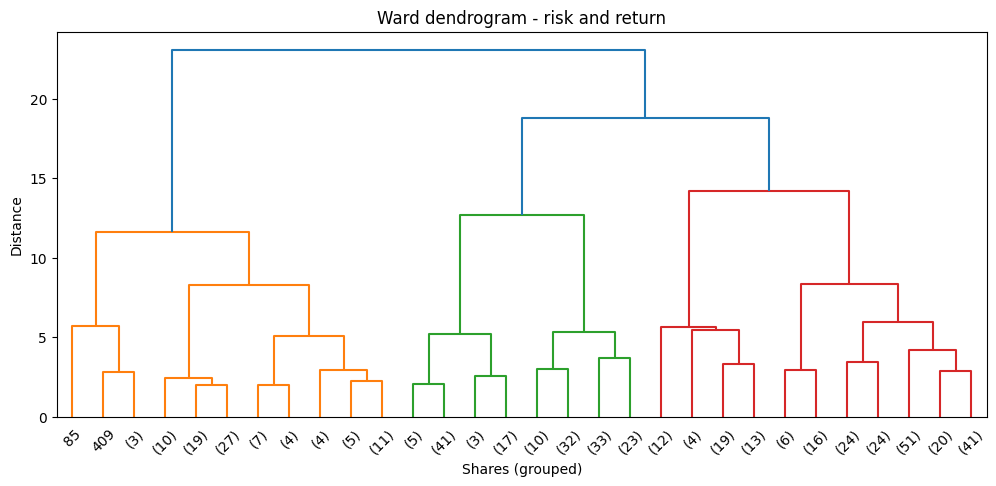

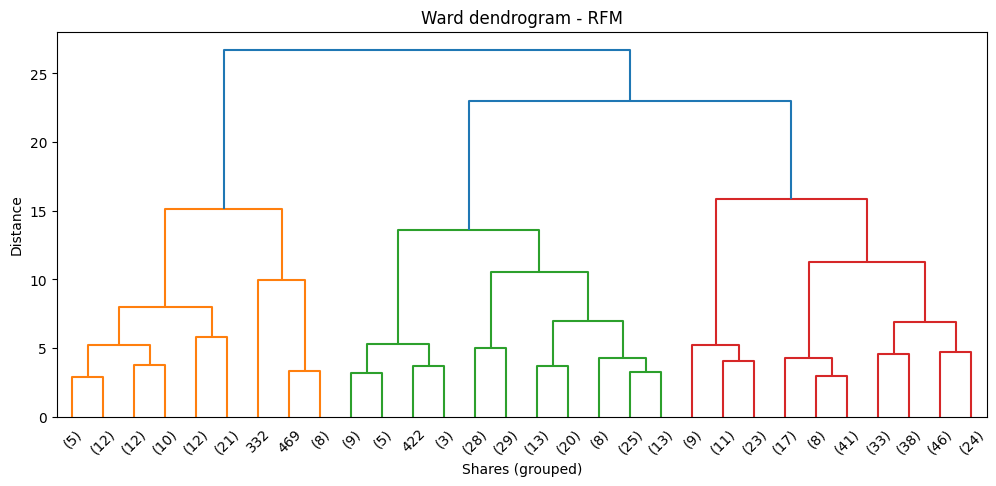

In [41]:
# Dendrogram for the risk-return matrix
plt.figure(figsize=(12, 5))
dendrogram(linkage(X_rr_scaled, method='ward'), truncate_mode='lastp', p=30)
plt.title('Ward dendrogram - risk and return')
plt.xlabel('Shares (grouped)')
plt.ylabel('Distance')
plt.show()

# Dendrogram for the RFM matrix
plt.figure(figsize=(12, 5))
dendrogram(linkage(X_rfm_scaled, method='ward'), truncate_mode='lastp', p=30)
plt.title('Ward dendrogram - RFM')
plt.xlabel('Shares (grouped)')
plt.ylabel('Distance')
plt.show()

In [42]:
# Compare k = 2 to 8 using silhouette score and cluster sizes
for name, X in [('Risk-return', X_rr_scaled), ('RFM', X_rfm_scaled)]:
    print(name)
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        score = silhouette_score(X, labels)
        sizes = np.bincount(labels)
        print(f'  k={k}  silhouette={score:.3f}  sizes={sizes}')

Risk-return
  k=2  silhouette=0.339  sizes=[394  92]
  k=3  silhouette=0.274  sizes=[230  92 164]
  k=4  silhouette=0.282  sizes=[164  92 182  48]
  k=5  silhouette=0.304  sizes=[ 92  48 182  98  66]
  k=6  silhouette=0.320  sizes=[182  48  87  98  66   5]
  k=7  silhouette=0.324  sizes=[ 87  48 160  98  66   5  22]
  k=8  silhouette=0.321  sizes=[160  48   5  98  66  31  22  56]
RFM
  k=2  silhouette=0.368  sizes=[404  82]
  k=3  silhouette=0.304  sizes=[250  82 154]
  k=4  silhouette=0.289  sizes=[ 82 207 154  43]
  k=5  silhouette=0.305  sizes=[154 207  10  43  72]
  k=6  silhouette=0.314  sizes=[207 136  10  43  72  18]
  k=7  silhouette=0.292  sizes=[136  72  10  43 141  18  66]
  k=8  silhouette=0.302  sizes=[ 10  72  79  43 141  18  66  57]


## 2.3 K-means clustering
A random seed (`random_state=42`) makes results reproducible. `n_init=10` runs K-means 10 times with different starting centroids and keeps the best result.

Risk-return
  k=2  inertia=621.6  silhouette=0.387  sizes=[143 343]
  k=3  inertia=461.2  silhouette=0.329  sizes=[202 120 164]
  k=4  inertia=371.6  silhouette=0.327  sizes=[132 154  40 160]
  k=5  inertia=309.6  silhouette=0.341  sizes=[112 166 131  27  50]
  k=6  inertia=265.7  silhouette=0.326  sizes=[115  20  85 134  56  76]
  k=7  inertia=227.5  silhouette=0.331  sizes=[ 83  74 143  85   5  48  48]
  k=8  inertia=196.0  silhouette=0.353  sizes=[143  81  82   5  77  36  34  28]
RFM
  k=2  inertia=1066.8  silhouette=0.423  sizes=[418  68]
  k=3  inertia=796.7  silhouette=0.325  sizes=[272  63 151]
  k=4  inertia=609.8  silhouette=0.341  sizes=[122  92  61 211]
  k=5  inertia=514.7  silhouette=0.358  sizes=[ 68 122  87  11 198]
  k=6  inertia=437.4  silhouette=0.346  sizes=[104 120 141  69  11  41]
  k=7  inertia=393.0  silhouette=0.341  sizes=[147  17  66 109  48  11  88]
  k=8  inertia=342.2  silhouette=0.350  sizes=[ 15 106  64  66   1  11 140  83]


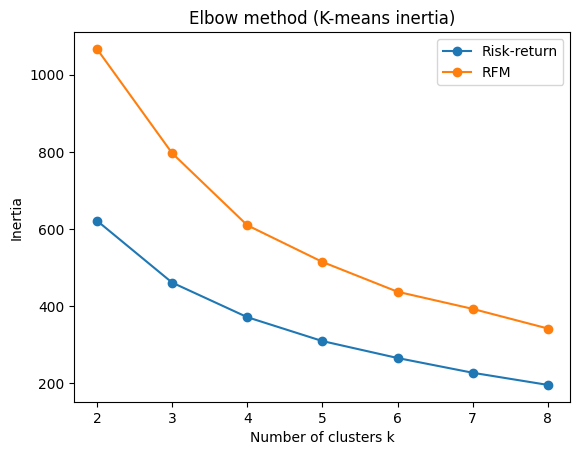

In [43]:
# Compare k = 2 to 8 using silhouette score, inertia and cluster sizes
for name, X in [('Risk-return', X_rr_scaled), ('RFM', X_rfm_scaled)]:
    print(name)
    inertias = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inertias.append(km.inertia_)
        score = silhouette_score(X, km.labels_)
        sizes = np.bincount(km.labels_)
        print(f'  k={k}  inertia={km.inertia_:.1f}  silhouette={score:.3f}  sizes={sizes}')

    # Elbow plot
    plt.plot(range(2, 9), inertias, marker='o', label=name)
plt.title('Elbow method (K-means inertia)')
plt.xlabel('Number of clusters k')
plt.ylabel('Inertia')
plt.legend()
plt.show()

In [44]:
# Why multiple initialisations matter: one start vs ten starts
for n in [1, 10]:
    km = KMeans(n_clusters=3, n_init=n, random_state=0).fit(X_rfm_scaled)
    print(f'n_init={n}: inertia = {km.inertia_:.2f}')

n_init=1: inertia = 813.93
n_init=10: inertia = 796.61


### Selected number of clusters
Choose k after reading the dendrograms, silhouette scores, cluster sizes and elbow plot (avoid k values that create very small clusters).

In [45]:
# Set your chosen k values here
k_rr = 2
k_rfm = 3

# Four baseline solutions
df['Ward_RR'] = AgglomerativeClustering(n_clusters=k_rr, linkage='ward').fit_predict(X_rr_scaled)
df['KMeans_RR'] = KMeans(n_clusters=k_rr, n_init=10, random_state=42).fit_predict(X_rr_scaled)
df['Ward_RFM'] = AgglomerativeClustering(n_clusters=k_rfm, linkage='ward').fit_predict(X_rfm_scaled)
df['KMeans_RFM'] = KMeans(n_clusters=k_rfm, n_init=10, random_state=42).fit_predict(X_rfm_scaled)

# Reset the index to turn the 'Ticker' index into a column, and show the head
df_display = df.reset_index()
df_display[['Ticker', 'Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']].head()

,Ticker,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM
0,MMM,0,1,2,0
1,AOS,0,1,0,0
2,ABT,0,1,2,2
3,ABBV,0,1,2,2
4,ACN,0,1,2,2


## 2.4 Cluster profiles and algorithm comparison

In [46]:
# Profiles in original units (mean of each cluster)
df['Return_%'] = df['Mean_Weekly_Return'] * 100
df['Monetary_billion'] = df['Monetary'] / 1e9

print('Ward risk-return')
print(df.groupby('Ward_RR')[['Return_%', 'Weekly_Beta']].mean().round(3), '\n')
print('K-means risk-return')
print(df.groupby('KMeans_RR')[['Return_%', 'Weekly_Beta']].mean().round(3), '\n')
print('Ward RFM')
print(df.groupby('Ward_RFM')[['Recency', 'Frequency', 'Monetary_billion']].mean().round(2), '\n')
print('K-means RFM')
print(df.groupby('KMeans_RFM')[['Recency', 'Frequency', 'Monetary_billion']].mean().round(2))

Ward risk-return
         Return_%  Weekly_Beta
Ward_RR                       
0           0.205        0.898
1           0.632        1.298 

K-means risk-return
           Return_%  Weekly_Beta
KMeans_RR                       
0             0.533        1.350
1             0.183        0.817 

Ward RFM
          Recency  Frequency  Monetary_billion
Ward_RFM                                      
0           12.12       3.36             11.76
1           58.30       2.10             47.16
2           13.68       2.86             80.15 

K-means RFM
            Recency  Frequency  Monetary_billion
KMeans_RFM                                      
0             13.48       3.35             12.06
1             65.06       1.68             55.09
2             14.25       2.89             82.12


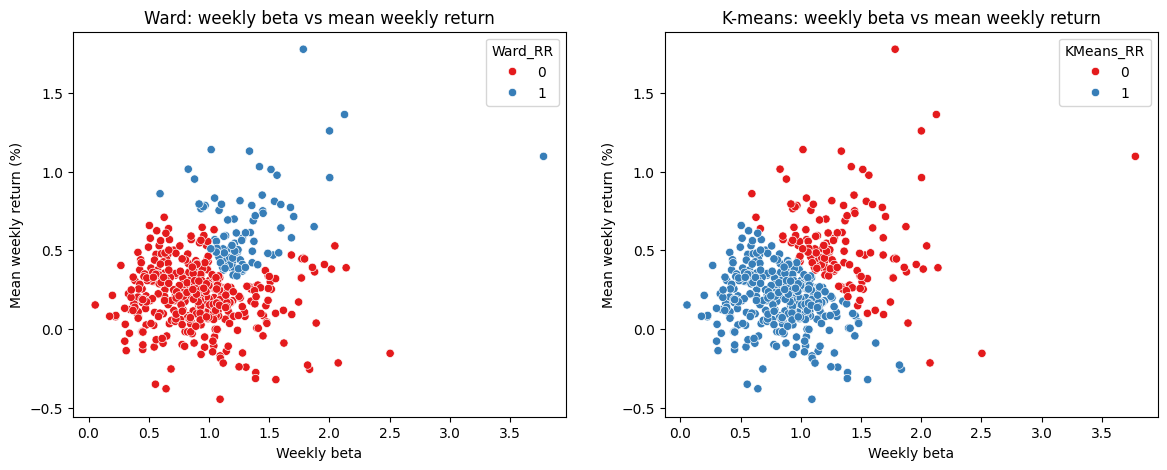

In [47]:
# Risk-return has only 2 features, so plot them directly
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='Weekly_Beta', y='Return_%', hue='Ward_RR', palette='Set1', ax=axes[0])
axes[0].set_title('Ward: weekly beta vs mean weekly return')
sns.scatterplot(data=df, x='Weekly_Beta', y='Return_%', hue='KMeans_RR', palette='Set1', ax=axes[1])
axes[1].set_title('K-means: weekly beta vs mean weekly return')
for ax in axes:
    ax.set_xlabel('Weekly beta'); ax.set_ylabel('Mean weekly return (%)')
plt.show()

Variance explained by PC1 and PC2: [0.458 0.336]


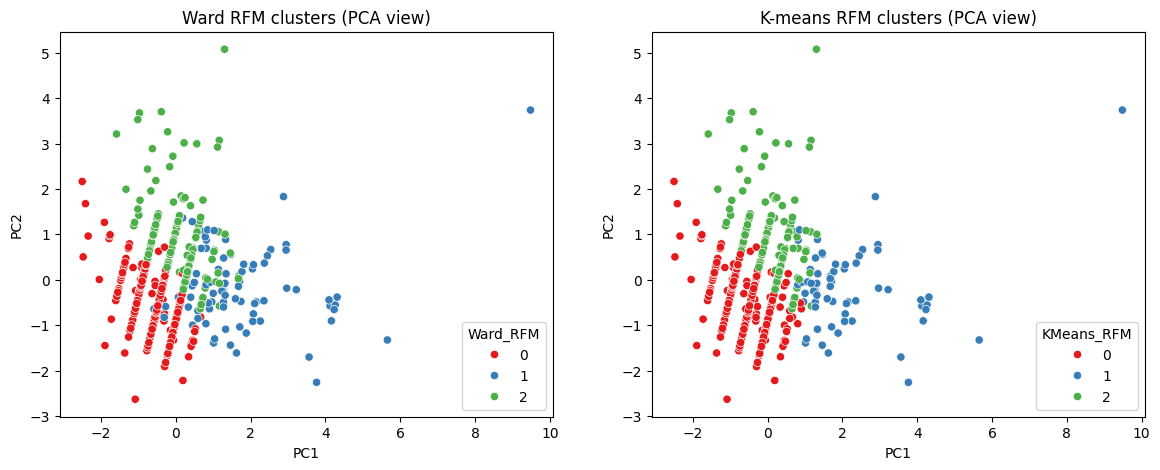

In [48]:
# RFM has 3 features, so PCA reduces them to 2 components for plotting
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_rfm_scaled)
print('Variance explained by PC1 and PC2:', pca.explained_variance_ratio_.round(3))
df['PC1'] = pcs[:, 0]
df['PC2'] = pcs[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='PC1', y='PC2', hue='Ward_RFM', palette='Set1', ax=axes[0])
axes[0].set_title('Ward RFM clusters (PCA view)')
sns.scatterplot(data=df, x='PC1', y='PC2', hue='KMeans_RFM', palette='Set1', ax=axes[1])
axes[1].set_title('K-means RFM clusters (PCA view)')
plt.show()

In [49]:
# Compare Ward and K-means on the same shares
# Adjusted Rand index (ARI): 1 = identical groups, 0 = no better than chance
print('ARI risk-return (Ward vs K-means):', round(adjusted_rand_score(df['Ward_RR'], df['KMeans_RR']), 3))
print(pd.crosstab(df['Ward_RR'], df['KMeans_RR']), '\n')
print('ARI RFM (Ward vs K-means):', round(adjusted_rand_score(df['Ward_RFM'], df['KMeans_RFM']), 3))
print(pd.crosstab(df['Ward_RFM'], df['KMeans_RFM']))

ARI risk-return (Ward vs K-means): 0.598
KMeans_RR   0    1
Ward_RR           
0          51  343
1          92    0 

ARI RFM (Ward vs K-means): 0.822
KMeans_RFM    0   1    2
Ward_RFM                
0           250   0    0
1            16  58    8
2             6   5  143


## 2.5 RFM sensitivity
### 2.5.1 Correlation analysis

           Recency  Frequency  log_M
Recency      1.000     -0.346  0.152
Frequency   -0.346      1.000  0.013
log_M        0.152      0.013  1.000


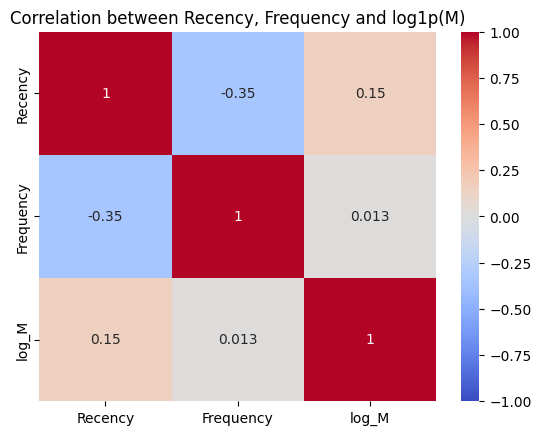

In [50]:
corr = df[['Recency', 'Frequency', 'log_M']].corr()
print(corr.round(3))

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between Recency, Frequency and log1p(M)')
plt.show()

### 2.5.2 Removal of Monetary
Same shares, same k, R and F only, standardised again.

In [51]:
X_rf_scaled = StandardScaler().fit_transform(df[['Recency', 'Frequency']])
df['Ward_RF'] = AgglomerativeClustering(n_clusters=k_rfm, linkage='ward').fit_predict(X_rf_scaled)

print('ARI Ward RFM vs Ward RF (without M):', round(adjusted_rand_score(df['Ward_RFM'], df['Ward_RF']), 3))
print(pd.crosstab(df['Ward_RFM'], df['Ward_RF'], rownames=['With M'], colnames=['Without M']))

ARI Ward RFM vs Ward RF (without M): 0.291
Without M   0    1   2
With M                
0           1  183  66
1          79    3   0
2           9   86  59


With M
          Recency  Frequency  Monetary_billion
Ward_RFM                                      
0            11.0        3.0             11.18
1            54.5        2.0             17.85
2            11.0        3.0             39.70 

Without M
         Recency  Frequency  Monetary_billion
Ward_RF                                      
0           54.0        2.0             20.85
1           11.0        4.0             14.86
2           11.0        2.0             17.70


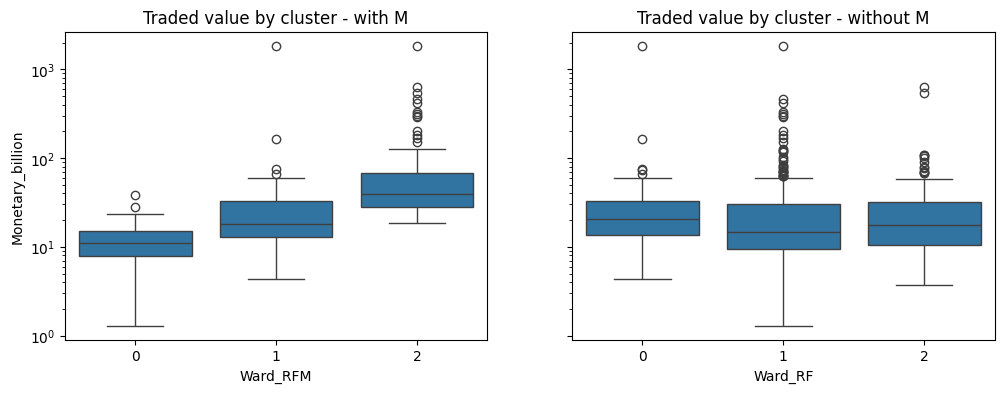

In [52]:
# Compare traded value (M) profiles with and without Monetary
print('With M')
print(df.groupby('Ward_RFM')[['Recency', 'Frequency', 'Monetary_billion']].median().round(2), '\n')
print('Without M')
print(df.groupby('Ward_RF')[['Recency', 'Frequency', 'Monetary_billion']].median().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.boxplot(data=df, x='Ward_RFM', y='Monetary_billion', ax=axes[0]); axes[0].set_title('Traded value by cluster - with M')
sns.boxplot(data=df, x='Ward_RF', y='Monetary_billion', ax=axes[1]);  axes[1].set_title('Traded value by cluster - without M')
axes[0].set_yscale('log')
plt.show()

In [53]:
# Save the feature table with cluster assignments
df.to_csv('task2_clusters.csv', index=False)
print('Saved task2_clusters.csv')

Saved task2_clusters.csv


# Task 3 – Business Intelligence and Critical Review

In [54]:
# Part 0: Import libraries and collect everything into one table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score

observation_date = '2024-12-31'

# Load original features table properly (stored as 'df' in the workspace)
table = df.copy()
table['log1p_M'] = np.log1p(table['Monetary'])

# Add the sector of each share (Wikipedia uses BRK.B, Yahoo uses BRK-B)
sp500['Symbol'] = sp500['Symbol'].str.replace('.', '-', regex=False)
sector = sp500.set_index('Symbol')['GICS Sector']
table['Sector'] = sector.reindex(table['Ticker'].values).values

print('Number of shares:', len(table))
table.head()

Number of shares: 486


,Ticker,Sector,Mean_Weekly_Return,Weekly_Beta,Weekly_Obs,Recency,Frequency,Monetary,Common_Set,log_M,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM,Return_%,Monetary_billion,PC1,PC2,Ward_RF,log1p_M
0,MMM,Industrials,0.001142,0.869079,207,11,4,2.599146e+10,True,23.981034,0,1,2,0,0.114247,25.991459,-0.722696,0.586181,1,23.981034
1,AOS,Industrials,0.001991,1.042804,207,11,2,4.748980e+09,True,22.281196,0,1,0,0,0.199066,4.748980,-0.228572,-1.671776,2,22.281196
2,ABT,Health Care,0.000971,0.583542,207,11,1,3.523027e+10,True,24.285172,0,1,2,2,0.097133,35.230273,0.830365,-0.025484,2,24.285172
3,ABBV,Health Care,0.003749,0.425366,207,11,3,6.837054e+10,True,24.948208,0,1,2,2,0.374916,68.370538,0.041292,1.224235,1,24.948208
4,ACN,Information Technology,0.002376,1.143299,207,11,2,5.199430e+10,True,24.674400,0,1,2,2,0.237638,51.994299,0.452246,0.655495,2,24.674400


## 3.1 Data mart: fact and dimension tables
Grain of the main fact table = one share on one trading date.

In [64]:
# List of included shares (tickers)
shares = table['Ticker'].values if 'Ticker' in table.columns else table.index

# Dimension tables
dim_share = pd.DataFrame({'Ticker': shares, 'Sector': table['Sector'].values})
dim_sector = pd.DataFrame({'Sector': table['Sector'].unique()})
dim_benchmark = pd.DataFrame({'Benchmark': ['^GSPC'], 'Price_basis': ['Adj Close'], 'Currency': ['USD']})

dim_date = pd.DataFrame({'Date': close.index})
dim_date['Week_ending_Friday'] = dim_date['Date'].dt.to_period('W-FRI').dt.end_time.dt.date
dim_date['Month'] = dim_date['Date'].dt.month
dim_date['Year'] = dim_date['Date'].dt.year

# Fact table 1: daily observations (one share on one date)
fact_daily = pd.DataFrame({
    'Close': close[shares].stack(),
    'Adj_Close': adj[shares].stack(),
    'Volume': volume[shares].stack()
}).reset_index()
fact_daily.columns = ['Date', 'Ticker', 'Close', 'Adj_Close', 'Volume']
fact_daily['Traded_value_USD'] = fact_daily['Close'] * fact_daily['Volume']

# Fact table 2: share features (one share per observation date)
fact_features = table[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].copy()
fact_features.insert(0, 'Ticker', shares)
fact_features['Observation_date'] = observation_date
fact_features['Run_id'] = 1

# Fact table 3: cluster assignments (one share per run)
fact_clusters = table[['Ward_RR', 'Ward_RFM', 'KMeans_RR', 'KMeans_RFM', 'Ward_RF']].copy()
fact_clusters.insert(0, 'Ticker', shares)
fact_clusters['Run_id'] = 1

# Provenance: one row describing how this run was calculated
run_info = pd.DataFrame([{
    'Run_id': 1,
    'Data_source': 'yfinance',
    'Ticker_list_date': '2026-10-20',      # change to the date you scraped Wikipedia
    'Study_period': '2021-01-01 to 2025-01-01 (end exclusive)',
    'Observation_date': observation_date,
    'Baseline_window': 20, 'RFM_window': 60, 'Volume_threshold': '2 x mean',
    'Scaling': 'log1p(M) then StandardScaler',
    'Random_seed': 42,
    'Pandas_version': pd.__version__,
    'Code_version': 'v1.0'
}])

# Save every table so the results can be reproduced
dim_share.to_csv('dim_share.csv', index=False)
dim_sector.to_csv('dim_sector.csv', index=False)
dim_benchmark.to_csv('dim_benchmark.csv', index=False)
dim_date.to_csv('dim_date.csv', index=False)
fact_daily.to_csv('fact_daily.csv', index=False)
fact_features.to_csv('fact_features.csv', index=False)
fact_clusters.to_csv('fact_clusters.csv', index=False)
run_info.to_csv('run_info.csv', index=False)

print('fact_daily rows:', len(fact_daily))
run_info

fact_daily rows: 488430


,Run_id,Data_source,Ticker_list_date,Study_period,Observation_date,Baseline_window,RFM_window,Volume_threshold,Scaling,Random_seed,Pandas_version,Code_version
0,1,yfinance,2026-10-20,2021-01-01 to 2025-01-01 (end exclusive),2024-12-31,20,60,2 x mean,log1p(M) then StandardScaler,42,2.2.3,v1.0


In [68]:
# Table 3.1: summary of the data mart tables (built from the real tables)
tables = {
    'fact_daily': (fact_daily, 'Fact', 'share x trading date'),
    'fact_features': (fact_features, 'Fact (derived)', 'share x observation date x run'),
    'fact_clusters': (fact_clusters, 'Fact (derived)', 'share x run'),
    'dim_date': (dim_date, 'Dimension (time)', 'trading date'),
    'dim_share': (dim_share, 'Dimension (share)', 'share'),
    'dim_sector': (dim_sector, 'Dimension (sector)', 'GICS sector'),
    'dim_benchmark': (dim_benchmark, 'Dimension (benchmark)', 'benchmark'),
    'run_info': (run_info, 'Provenance', 'calculation run'),
}

rows = []
for name, (t, kind, grain) in tables.items():
    rows.append({
        'Table': name,
        'Type': kind,
        'Grain (one row per...)': grain,
        'Rows': len(t),
        'Columns': ', '.join(t.columns)
    })

table_3_1 = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', None)
table_3_1

,Table,Type,Grain (one row per...),Rows,Columns
0,fact_daily,Fact,share x trading date,488430,"Date, Ticker, Close, Adj_Close, Volume, Traded_value_USD"
1,fact_features,Fact (derived),share x observation date x run,486,"Ticker, Mean_Weekly_Return, Weekly_Beta, Recency, Frequency, Monetary, Observation_date, Run_id"
2,fact_clusters,Fact (derived),share x run,486,"Ticker, Ward_RR, Ward_RFM, KMeans_RR, KMeans_RFM, Ward_RF, Run_id"
3,dim_date,Dimension (time),trading date,1005,"Date, Week_ending_Friday, Month, Year"
4,dim_share,Dimension (share),share,486,"Ticker, Sector"
5,dim_sector,Dimension (sector),GICS sector,11,Sector
6,dim_benchmark,Dimension (benchmark),benchmark,1,"Benchmark, Price_basis, Currency"
7,run_info,Provenance,calculation run,1,"Run_id, Data_source, Ticker_list_date, Study_period, Observation_date, Baseline_window, RFM_window, Volume_threshold, Scaling, Random_seed, Pandas_version, Code_version"


## 3.2.1 Cluster profiles in original units

In [56]:
# Risk-return clusters
profile_rr = table.groupby('Ward_RR')[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].mean()
profile_rr['Number_of_shares'] = table['Ward_RR'].value_counts()
profile_rr['Mean_Weekly_Return'] = profile_rr['Mean_Weekly_Return'] * 100   # in %
profile_rr['Monetary'] = profile_rr['Monetary'] / 1e9                                    # in USD billions
print('Table 3.2a: Ward risk-return clusters')
print(profile_rr.round(2))

# RFM clusters
profile_rfm = table.groupby('Ward_RFM')[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency', 'Frequency', 'Monetary']].mean()
profile_rfm['Number_of_shares'] = table['Ward_RFM'].value_counts()
profile_rfm['Mean_Weekly_Return'] = profile_rfm['Mean_Weekly_Return'] * 100
profile_rfm['Monetary'] = profile_rfm['Monetary'] / 1e9
print('\nTable 3.2b: Ward RFM clusters')
print(profile_rfm.round(2))

Table 3.2a: Ward risk-return clusters
         Mean_Weekly_Return  Weekly_Beta  Recency  Frequency  Monetary  \
Ward_RR                                                                  
0                      0.20          0.9    19.64       2.94     30.21   
1                      0.63          1.3    23.67       3.20     78.78   

         Number_of_shares  
Ward_RR                    
0                     394  
1                      92  

Table 3.2b: Ward RFM clusters
          Mean_Weekly_Return  Weekly_Beta  Recency  Frequency  Monetary  \
Ward_RFM                                                                  
0                       0.25         0.94    12.12       3.36     11.76   
1                       0.29         1.01    58.30       2.10     47.16   
2                       0.34         1.01    13.68       2.86     80.15   

          Number_of_shares  
Ward_RFM                    
0                      250  
1                       82  
2                      154  


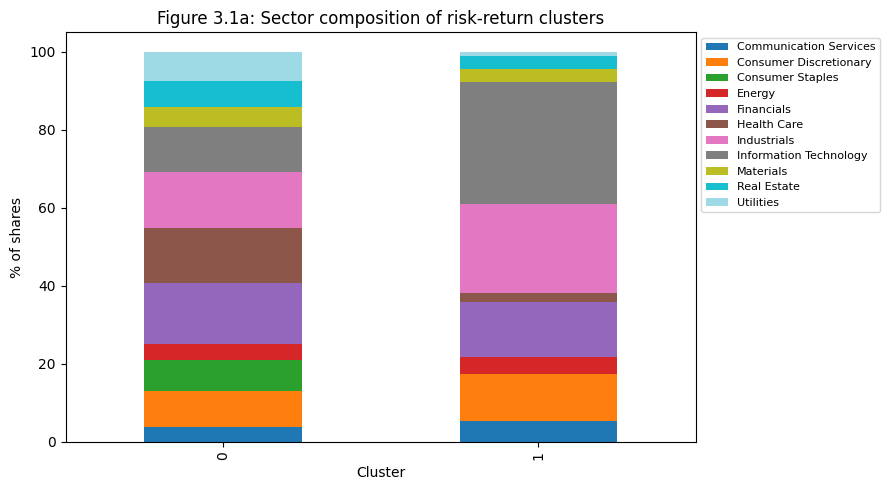

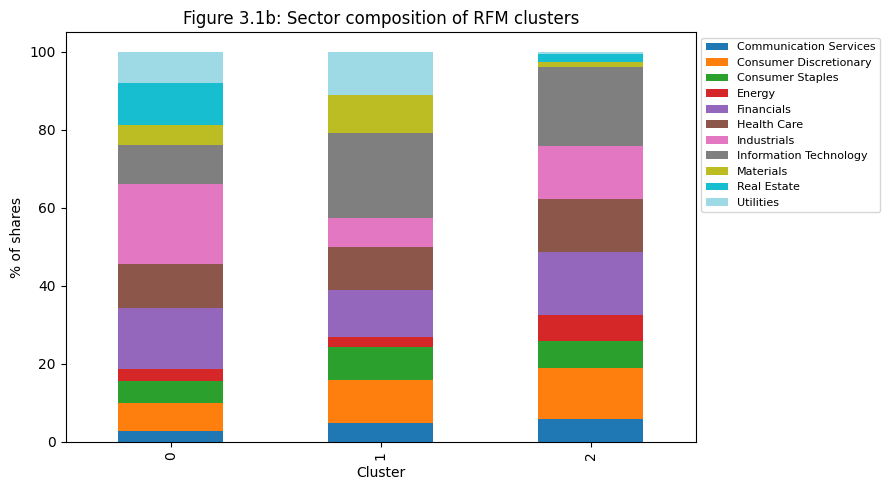

Sector   Communication Services  Consumer Discretionary  Consumer Staples  \
Ward_RR                                                                     
0                           3.8                     9.1               8.1   
1                           5.4                    12.0               0.0   

Sector   Energy  Financials  Health Care  Industrials  Information Technology  \
Ward_RR                                                                         
0           4.1        15.5         14.2         14.5                    11.4   
1           4.3        14.1          2.2         22.8                    31.5   

Sector   Materials  Real Estate  Utilities  
Ward_RR                                     
0              5.1          6.9        7.4  
1              3.3          3.3        1.1  
Sector    Communication Services  Consumer Discretionary  Consumer Staples  \
Ward_RFM                                                                     
0                            2

In [57]:
# Sector composition (% of shares in each cluster)
sector_rr = pd.crosstab(table['Ward_RR'], table['Sector'], normalize='index') * 100
sector_rfm = pd.crosstab(table['Ward_RFM'], table['Sector'], normalize='index') * 100

sector_rr.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='tab20')
plt.title('Figure 3.1a: Sector composition of risk-return clusters')
plt.ylabel('% of shares'); plt.xlabel('Cluster')
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

sector_rfm.plot(kind='bar', stacked=True, figsize=(9, 5), colormap='tab20')
plt.title('Figure 3.1b: Sector composition of RFM clusters')
plt.ylabel('% of shares'); plt.xlabel('Cluster')
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

print(sector_rr.round(1))
print(sector_rfm.round(1))

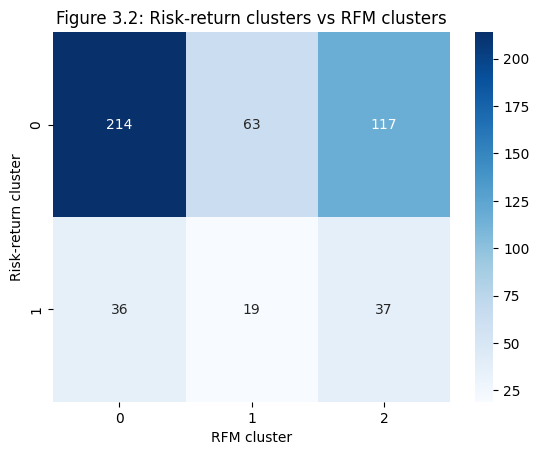

ARI risk-return vs RFM: 0.031


In [58]:
# Do the two kinds of cluster contain the same shares?
both = pd.crosstab(table['Ward_RR'], table['Ward_RFM'])
sns.heatmap(both, annot=True, fmt='d', cmap='Blues')
plt.title('Figure 3.2: Risk-return clusters vs RFM clusters')
plt.xlabel('RFM cluster'); plt.ylabel('Risk-return cluster')
plt.show()

print('ARI risk-return vs RFM:', round(adjusted_rand_score(table['Ward_RR'], table['Ward_RFM']), 3))

## 3.2.2 Sensitivity: correlations and removing Monetary

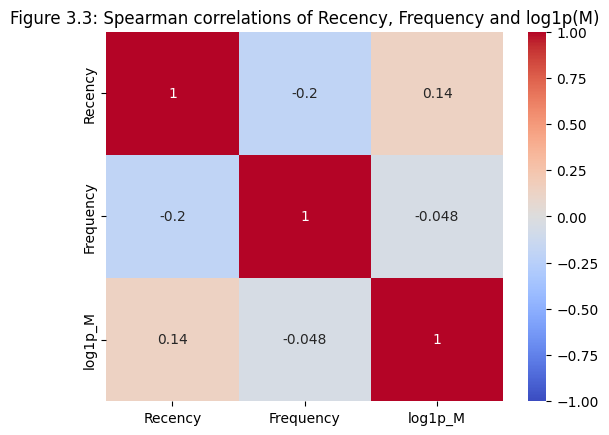

           Recency  Frequency  log1p_M
Recency       1.00      -0.20     0.14
Frequency    -0.20       1.00    -0.05
log1p_M       0.14      -0.05     1.00


In [59]:
corr = table[['Recency', 'Frequency', 'log1p_M']].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Figure 3.3: Spearman correlations of Recency, Frequency and log1p(M)')
plt.show()
print(corr.round(2))

ARI RFM vs RF only: 0.291
Ward_RF    0    1   2
Ward_RFM             
0          1  183  66
1         79    3   0
2          9   86  59

Median Monetary by RFM cluster:
Ward_RFM
0    11.18
1    17.85
2    39.70
Name: Monetary, dtype: float64

Median Monetary by RF-only cluster:
Ward_RF
0    20.85
1    14.86
2    17.70
Name: Monetary, dtype: float64


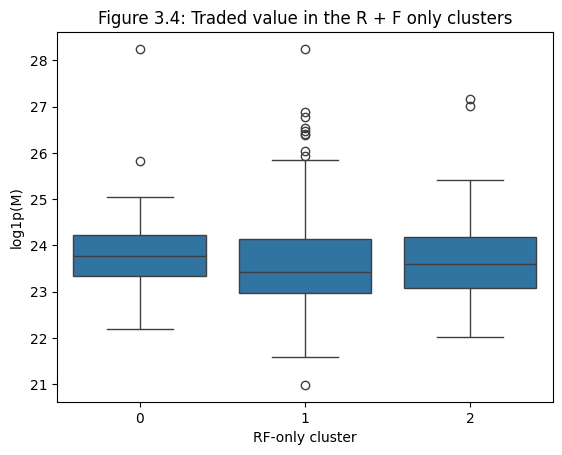

In [60]:
# Compare RFM clusters with R + F only clusters (same shares, same k)
print('ARI RFM vs RF only:', round(adjusted_rand_score(table['Ward_RFM'], table['Ward_RF']), 3))
print(pd.crosstab(table['Ward_RFM'], table['Ward_RF']))

# Median traded value (USD billions) in each cluster
print('\nMedian Monetary by RFM cluster:')
print((table.groupby('Ward_RFM')['Monetary'].median() / 1e9).round(2))
print('\nMedian Monetary by RF-only cluster:')
print((table.groupby('Ward_RF')['Monetary'].median() / 1e9).round(2))

sns.boxplot(data=table, x='Ward_RF', y='log1p_M')
plt.title('Figure 3.4: Traded value in the R + F only clusters')
plt.xlabel('RF-only cluster'); plt.ylabel('log1p(M)')
plt.show()

## 3.2.3 Limitations: do shares in the same cluster still move together?

In [61]:
corr_all = weekly_returns[table['Ticker']].corr()

# Average correlation between ALL pairs of shares
n = len(corr_all)
avg_all = (corr_all.values.sum() - n) / (n * (n - 1))
print('Average correlation, all pairs:', round(avg_all, 3))

# Average correlation between shares in the SAME risk-return cluster
for c in sorted(table['Ward_RR'].unique()):
    members = table.loc[table['Ward_RR'] == c, 'Ticker']
    sub = corr_all.loc[members, members]
    k = len(members)
    avg = (sub.values.sum() - k) / (k * (k - 1))
    print('Cluster', c, 'average correlation within cluster:', round(avg, 3))

Average correlation, all pairs: 0.3
Cluster 0 average correlation within cluster: 0.297
Cluster 1 average correlation within cluster: 0.374


In [62]:
# Price basis check: Adj Close / Close changes when dividends are adjusted
# Using the active daily price DataFrames 'adj' and 'close'
ratio = adj[table['Ticker']] / close[table['Ticker']]
change = ratio.max() - ratio.min()
print('Shares with Adj/Close ratio change above 10%:', (change > 0.10).sum())

Shares with Adj/Close ratio change above 10%: 128
